In [ ]:
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
import plotly.colors as colors
pio.templates.default = "plotly_white"

In [4]:
data = pd.read_csv( "Sample - Superstore.csv" , encoding= "latin-1")

In [38]:
data.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Order Month,Order Year,Order Week
0,1,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136,11,2016,1
1,2,CA-2016-152156,2016-11-08,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820,11,2016,1
2,3,CA-2016-138688,2016-06-12,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714,6,2016,6
3,4,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310,10,2015,6
4,5,US-2015-108966,2015-10-11,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164,10,2015,6


In [8]:
data['Order Date'] = pd.to_datetime(data['Order Date'])
data['Order Month'] = data['Order Date'].dt.month
data['Order Year'] = data['Order Date'].dt.year
data['Order Week'] = data['Order Date'].dt.dayofweek

# Monthly sales analysis


In [10]:
sales_by_month = data.groupby('Order Month')['Sales'].sum().reset_index()

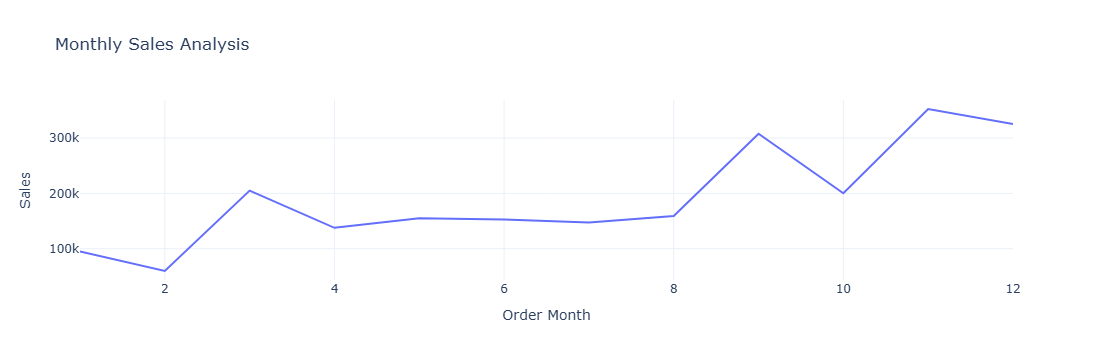

In [12]:
fig = px.line(sales_by_month,
              x = 'Order Month',
              y = 'Sales',
              title = "Monthly Sales Analysis")
fig.show()

# Sales by Categories

In [14]:
sales_by_categories = data.groupby("Category")["Sales"].sum().reset_index()

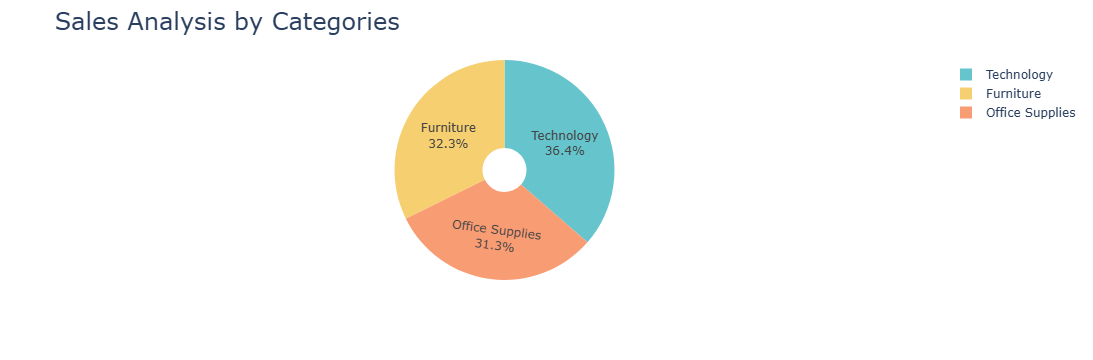

In [16]:
fig = px.pie(sales_by_categories,
    values="Sales", names="Category",
    hole=0.2 , color_discrete_sequence=px.colors.qualitative.Pastel
)
fig.update_traces(
    textposition="inside", textinfo="percent+label"
)
fig.update_layout(
    title_text='Sales Analysis by Categories', title_font=dict(size=24)
)
fig.show()

# Sales Analysis by Sub_Categories

In [17]:
sales_by_Subcategories = data.groupby("Sub-Category")["Sales"].sum().reset_index()

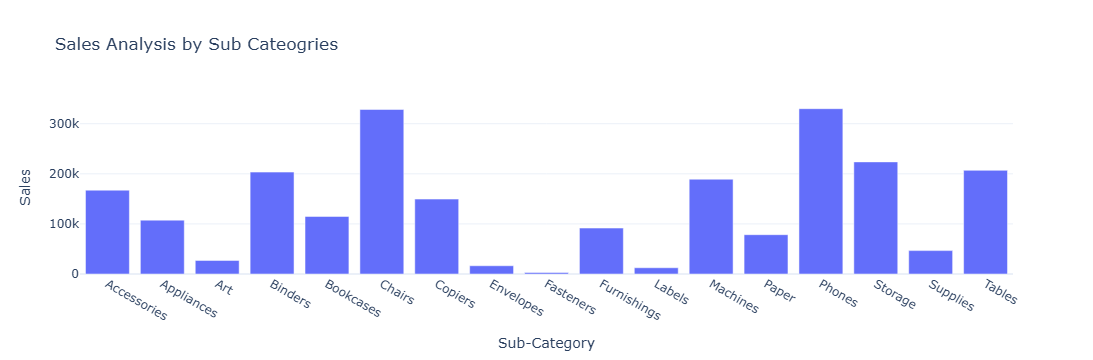

In [19]:
fig = px.bar(
    sales_by_Subcategories,
    x = 'Sub-Category',
    y = 'Sales',
    title = "Sales Analysis by Sub Cateogries"
)
fig.show()

# Monthly Profit Analysis

In [20]:
profit_by_month = data.groupby("Order Month")["Profit"].sum().reset_index()

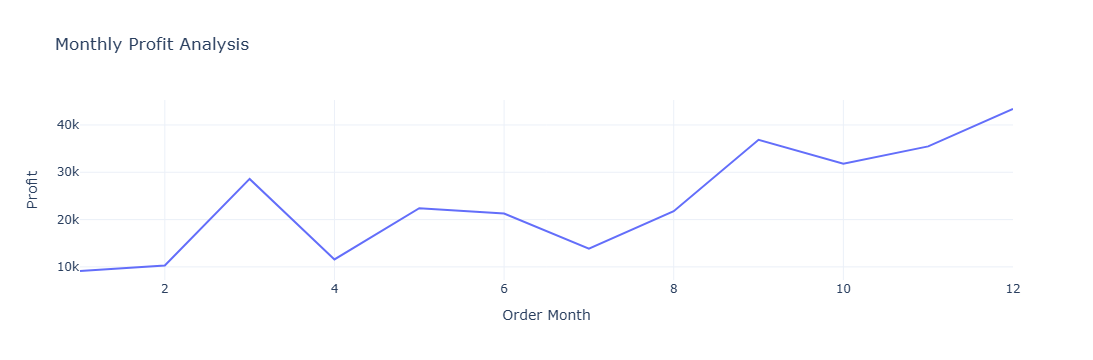

In [22]:
fig = px.line(profit_by_month,
              x = 'Order Month',
              y = 'Profit',
              title = "Monthly Profit Analysis")
fig.show()

# Profit by Category

In [23]:
profit_by_Category = data.groupby("Category")["Profit"].sum().reset_index()

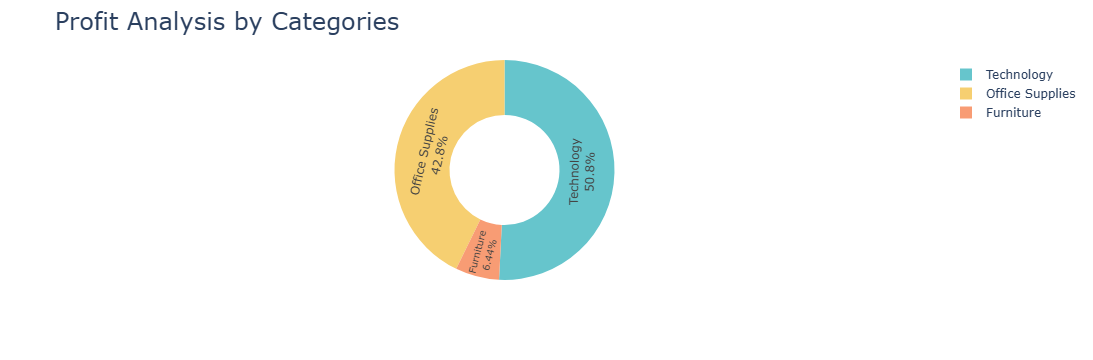

In [26]:
fig = px.pie( profit_by_Category,
    values="Profit", names="Category",
    hole=0.5 , color_discrete_sequence=px.colors.qualitative.Pastel
)
fig.update_traces(
    textposition="inside", textinfo="percent+label"
)
fig.update_layout(
    title_text='Profit Analysis by Categories', title_font=dict(size=24)
)
fig.show()

# Profit By Sub_Category

In [29]:
profit_by_SubCategory = data.groupby("Sub-Category")["Profit"].sum().reset_index()

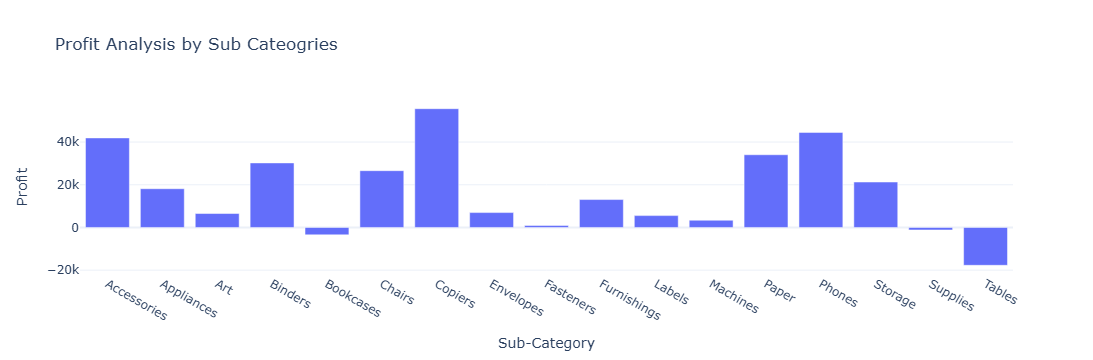

In [31]:
fig = px.bar(
    profit_by_SubCategory,
    x = 'Sub-Category',
    y = 'Profit',
    title = "Profit Analysis by Sub Cateogries"
)
fig.show()

# Sales and Profit for Customer Segment

In [32]:
Sales_Profit_by_Segment = data.groupby("Segment").agg({'Sales':'sum','Profit':'sum'}).reset_index()

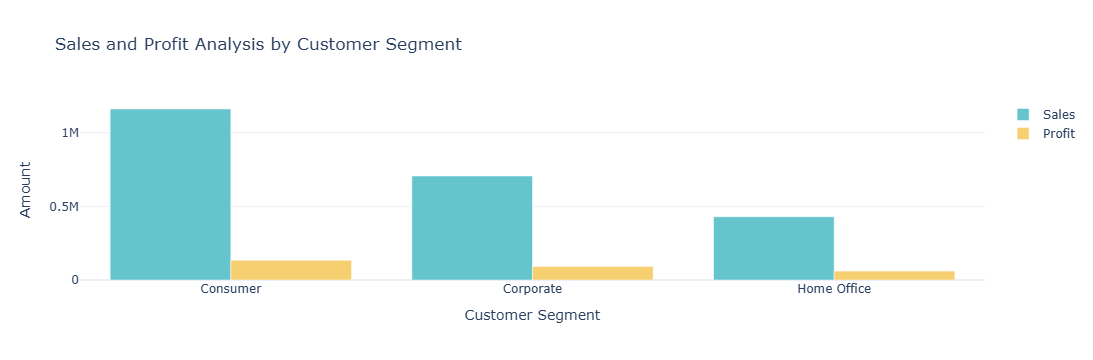

In [36]:
color_palette = colors.qualitative.Pastel
fig = go.Figure()
fig.add_trace(go.Bar(
    x=Sales_Profit_by_Segment['Segment'], y=Sales_Profit_by_Segment['Sales'] , name='Sales', marker_color=color_palette[0]
))fig.add_trace(go.Bar(
    x=Sales_Profit_by_Segment['Segment'] , y=Sales_Profit_by_Segment['Profit'] , name='Profit', marker_color=color_palette[1]
))fig.update_layout(
    title='Sales and Profit Analysis by Customer Segment', xaxis_title='Customer Segment', yaxis_title='Amount'
)fig.show()

# Sales to Profit Ratio

In [37]:
sales_profit_by_segment = data.groupby('Segment').agg({
    'Sales': 'sum','Profit': 'sum'
}).reset_index()
sales_profit_by_segment['Sales_to_Profit_Ratio'] = ( sales_profit_by_segment['Sales'] / sales_profit_by_segment['Profit']
)
print(sales_profit_by_segment[['Segment', 'Sales_to_Profit_Ratio']])

       Segment  Sales_to_Profit_Ratio
0     Consumer               8.659471
1    Corporate               7.677245
2  Home Office               7.125416
